#Upload Dataset Files

Before running the code cell below, please download the following 7 files and upload them when you execute the cell.

**1. SentiMix Files (4 files):**
* Download `Train.txt`, `Validation.txt`, and `Test.txt` from the [Dataset folder](https://github.com/singhnivedita/SemEval2020-Task9/tree/master/Pre%20Processing%20Code/Original%20Dataset).
* Download `Ty.txt` from the [Datasets folder](https://github.com/singhnivedita/SemEval2020-Task9/blob/master/Fully%20Processed%20Datasets/Ty.txt).

**2. Dakshina Files (3 files):**
* Download the dataset from the [Google Research Dakshina repository](https://github.com/google-research-datasets/dakshina).
* Once downloaded and extracted, open the dataset folder and navigate into the **`hi`** (Hindi) directory, and then into the **`lexicons`** directory.
* From inside that `lexicons` folder, copy out these three specific files:
  * `hi.translit.sampled.train.tsv`
  * `hi.translit.sampled.dev.tsv`
  * `hi.translit.sampled.test.tsv`

**Note:** The code execution will pause until you select and upload all 7 of these files. Ensure you upload them all so the pipeline runs successfully.

In [1]:
import os
import shutil
from pathlib import Path
from google.colab import files

data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

required_files = {
    "Train.txt",
    "Validation.txt",
    "Test.txt",
    "Ty.txt",
    "hi.translit.sampled.train.tsv",
    "hi.translit.sampled.dev.tsv",
    "hi.translit.sampled.test.tsv"
}

while True:
    existing_files = set(f.name for f in data_dir.iterdir() if f.is_file())
    missing_files = required_files - existing_files

    if not missing_files:
        print(f"\nSuccess! All 7 required files are now in the '{data_dir}' directory.")
        break

    print("\nYou are missing the following files:")
    for f in missing_files:
        print(f" - {f}")
    print("\nPlease upload the missing files. (You can do this in multiple batches if they are in different folders).")

    uploaded = files.upload()
    for filename in uploaded.keys():
        destination = data_dir / filename
        if destination.exists():
            destination.unlink()
        shutil.move(filename, destination)


You are missing the following files:
 - hi.translit.sampled.train.tsv
 - Validation.txt
 - Train.txt
 - Ty.txt
 - hi.translit.sampled.test.tsv
 - hi.translit.sampled.dev.tsv
 - Test.txt

Please upload the missing files. (You can do this in multiple batches if they are in different folders).


Saving hi.translit.sampled.dev.tsv to hi.translit.sampled.dev.tsv
Saving hi.translit.sampled.test.tsv to hi.translit.sampled.test.tsv
Saving hi.translit.sampled.train.tsv to hi.translit.sampled.train.tsv
Saving Test.txt to Test.txt
Saving Train.txt to Train.txt
Saving Ty.txt to Ty.txt
Saving Validation.txt to Validation.txt

Success! All 7 required files are now in the 'data' directory.


# Task 1: Classical Baseline Pipeline

###Import necessary libraries and configure local file paths


In [2]:
import re
import csv
import numpy as np
from pathlib import Path
from collections import Counter, defaultdict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.metrics import f1_score, classification_report
# import transformers
# import logging
# # import warnings
# transformers.logging.set_verbosity_error()


# warnings.filterwarnings("ignore")
data_dir = Path("data")
sentimix_paths = {
    "train": data_dir / "Train.txt",
    "val": data_dir / "Validation.txt",
    "test": data_dir / "Test.txt",
    "labels": data_dir / "Ty.txt"
}
dakshina_paths = [
    data_dir / f"hi.translit.sampled.{split}.tsv" for split in ["train", "dev", "test"]
]

random_seed = 42
sentiment_classes = ["negative", "neutral", "positive"]

###Read tweet files, clean URLs and usernames, attach test labels, and deduplicate to build the final dataset pool.

In [3]:
def clean_tokens_and_tags(tokens, tags):
    cleaned_tokens = []
    cleaned_tags = []
    i = 0
    url_pattern = re.compile(r"^(/+|:|\.|t|co|tco|c)$|…$")

    while i < len(tokens):
        word = tokens[i]
        if word.lower().startswith("http"):
            i += 1
            while i < len(tokens) and url_pattern.search(tokens[i]):
                i += 1
            if i < len(tokens) and tokens[i-1].endswith("/"):
                i += 1
        elif word.startswith("@"):
            i += 1
            if re.fullmatch(r"@_*", word) and i < len(tokens) and re.fullmatch(r"\w+", tokens[i]):
                i += 1
            while i < len(tokens) and re.fullmatch(r"_+", tokens[i]):
                i += 1
                if i < len(tokens) and re.fullmatch(r"\w+", tokens[i]):
                    i += 1
            cleaned_tokens.append("@user")
            cleaned_tags.append("univ")
        else:
            cleaned_tokens.append(word)
            cleaned_tags.append(tags[i])
            i += 1
    return cleaned_tokens, cleaned_tags

def load_and_clean_tweets(filepath):
    tweets = []
    header_pattern = re.compile(r"^meta\t(\d+)(?:\t(positive|negative|neutral))?$")
    tag_mapping = {"Hin": "hi", "Eng": "en", "O": "univ", "EMT": "univ"}

    with open(filepath, encoding="utf-8") as file:
        for line in file:
            line = line.rstrip("\n")
            header_match = header_pattern.match(line)
            if header_match:
                tweets.append({
                    "id": header_match.group(1),
                    "label": header_match.group(2),
                    "tokens": [],
                    "tags": []
                })
            elif line.strip():
                parts = line.split("\t")
                tag = parts[1].strip('"') if len(parts) > 1 else ""
                tweets[-1]["tokens"].append(parts[0])
                tweets[-1]["tags"].append(tag_mapping.get(tag, "univ"))

    for tweet in tweets:
        tweet["tokens"], tweet["tags"] = clean_tokens_and_tags(tweet["tokens"], tweet["tags"])

    return tweets

train_raw = load_and_clean_tweets(sentimix_paths["train"])
val_raw = load_and_clean_tweets(sentimix_paths["val"])
test_raw = load_and_clean_tweets(sentimix_paths["test"])

with open(sentimix_paths["labels"], encoding="utf-8") as file:
    test_labels_map = {row["Uid"]: row["Sentiment"] for row in csv.DictReader(file)}

for tweet in test_raw:
    tweet["label"] = test_labels_map[tweet["id"]]

tweet_pool = []
seen_tweet_ids = set()

for tweet in train_raw + val_raw + test_raw:
    if tweet["id"] not in seen_tweet_ids:
        seen_tweet_ids.add(tweet["id"])
        tweet_pool.append(tweet)

###Create Partition A and train the Language Identification (LID) classifier

In [4]:
rng = np.random.default_rng(random_seed)
shuffled_indices = rng.permutation(len(tweet_pool))
third_splits = np.array_split(shuffled_indices, 3)

partition_a = [tweet_pool[i] for i in third_splits[0]]

train_size = int(0.8 * len(partition_a))
val_size = int(0.1 * len(partition_a))

train_split = partition_a[:train_size]
val_split = partition_a[train_size : train_size + val_size]
test_split = partition_a[train_size + val_size :]

lid_train_tokens = [token for tweet in train_split for token in tweet["tokens"]]
lid_train_tags = [tag for tweet in train_split for tag in tweet["tags"]]

lid_pipeline = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(1, 4)),
    LogisticRegression(penalty="l2", C=1.0, max_iter=1000, random_state=random_seed)
)
lid_pipeline.fit(lid_train_tokens, lid_train_tags)

for split in (train_split, val_split, test_split):
    split_tokens = [token for tweet in split for token in tweet["tokens"]]
    split_predictions = lid_pipeline.predict(split_tokens).tolist()

    idx = 0
    for tweet in split:
        token_count = len(tweet["tokens"])
        tweet["lid_predictions"] = split_predictions[idx : idx + token_count]
        idx += token_count

###Build the Dakshina normalization dictionary and apply it to tokens predicted as Hindi

In [5]:
roman_counts = defaultdict(Counter)
for filepath in dakshina_paths:
    with open(filepath, encoding="utf-8") as file:
        for line in file:
            native, roman, count = line.rstrip("\n").split("\t")
            roman_counts[native][roman.lower()] += int(count)

best_romanizations = {}
for native, romans in roman_counts.items():
    canonical = romans.most_common(1)[0][0]
    for roman, count in romans.items():
        if roman not in best_romanizations or count > best_romanizations[roman][0]:
            best_romanizations[roman] = (count, canonical)

normalization_dict = {
    roman: canonical
    for roman, (count, canonical) in best_romanizations.items()
    if roman != canonical
}

def normalize_tokens(tokens, predicted_tags, norm_dict):
    normalized = []
    for word, tag in zip(tokens, predicted_tags):
        if tag == "hi":
            normalized.append(norm_dict.get(word.lower(), word))
        else:
            normalized.append(word)
    return normalized

for split in (train_split, val_split, test_split):
    for tweet in split:
        tweet["norm_tokens"] = normalize_tokens(
            tweet["tokens"],
            tweet["lid_predictions"],
            normalization_dict
        )

###Train the Random Forest sentiment classifier on normalized text, evaluate it, and save the processed splits for later tasks

In [6]:
import json

def combine_tokens(tweet):
    return " ".join(tweet["norm_tokens"])

train_texts = [combine_tokens(tweet) for tweet in train_split]
train_labels = [tweet["label"] for tweet in train_split]
test_texts = [combine_tokens(tweet) for tweet in test_split]
test_labels = [tweet["label"] for tweet in test_split]

sentiment_pipeline = make_pipeline(
    FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", token_pattern=r"\S+", ngram_range=(1, 3))),
        ("char", TfidfVectorizer(analyzer="char", ngram_range=(1, 3)))
    ]),
    RandomForestClassifier(n_estimators=300, max_depth=20, min_samples_leaf=5, random_state=random_seed, n_jobs=-1)
)

sentiment_pipeline.fit(train_texts, train_labels)
test_predictions = sentiment_pipeline.predict(test_texts)
test_macro_f1 = f1_score(test_labels, test_predictions, average="macro")

for split_name, split_data in [("train", train_split), ("validation", val_split), ("test", test_split)]:
    with open(data_dir / f"{split_name}.jsonl", "w", encoding="utf-8") as file:
        for tweet in split_data:
            file.write(json.dumps(tweet, ensure_ascii=False) + "\n")

with open(data_dir / "task1_results.json", "w") as file:
    json.dump({"test_macro_f1": test_macro_f1}, file)

test_macro_f1

0.5833074926441735

##Task 2: MuRIL Fine-Tuning Setup and Data Preparation

In [7]:
import json
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import f1_score

label_to_id = {"negative": 0, "neutral": 1, "positive": 2}

def load_partition_data(filename):
    with open(data_dir / filename, encoding="utf-8") as file:
        return [json.loads(line) for line in file]

train_data = load_partition_data("train.jsonl")
val_data = load_partition_data("validation.jsonl")
test_data = load_partition_data("test.jsonl")

train_raw_texts = [" ".join(tweet["tokens"]) for tweet in train_data]
train_labels = [label_to_id[tweet["label"]] for tweet in train_data]

val_raw_texts = [" ".join(tweet["tokens"]) for tweet in val_data]
val_labels = [label_to_id[tweet["label"]] for tweet in val_data]

test_raw_texts = [" ".join(tweet["tokens"]) for tweet in test_data]
test_norm_texts = [" ".join(tweet["norm_tokens"]) for tweet in test_data]
test_labels = [label_to_id[tweet["label"]] for tweet in test_data]

tokenizer = AutoTokenizer.from_pretrained("google/muril-base-cased")

class TweetDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.encodings = tokenizer(texts, truncation=True, padding=True, max_length=128)
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = TweetDataset(train_raw_texts, train_labels, tokenizer)
val_dataset = TweetDataset(val_raw_texts, val_labels, tokenizer)
test_raw_dataset = TweetDataset(test_raw_texts, test_labels, tokenizer)
test_norm_dataset = TweetDataset(test_norm_texts, test_labels, tokenizer)

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

###Load MuRIL, configure hyperparameters, fine-tune the model, and evaluate on both raw and normalized test sets

In [8]:
muril_model = AutoModelForSequenceClassification.from_pretrained(
    "google/muril-base-cased",
    num_labels=3,
    id2label={0: "negative", 1: "neutral", 2: "positive"},
    label2id={"negative": 0, "neutral": 1, "positive": 2}
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    macro_f1 = f1_score(labels, predictions, average="macro")
    return {"macro_f1": macro_f1}

training_args = TrainingArguments(
    output_dir="./muril_results",
    num_train_epochs=4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    report_to="none"
)

trainer = Trainer(
    model=muril_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_raw_dataset,
    compute_metrics=compute_metrics
)

trainer.train()

raw_evaluation = trainer.predict(test_raw_dataset)
norm_evaluation = trainer.predict(test_norm_dataset)

print(f"Task 2 RAW Test Macro-F1: {raw_evaluation.metrics['test_macro_f1']:.4f}")
print(f"Task 2 NORMALIZED Test Macro-F1: {norm_evaluation.metrics['test_macro_f1']:.4f}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Task 2 RAW Test Macro-F1: 0.6133
Task 2 NORMALIZED Test Macro-F1: 0.6138


##Task 3: LID-Augmented Data Preparation

###Encode the normalized text and assign the Task 1 LID tags to each MuRIL subword

In [9]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoModel

tag_to_id = {"en": 0, "hi": 1, "univ": 2}
special_tag_id = 3

def encode_with_aligned_tags(dataset):
    encodings = tokenizer(
        [tweet["norm_tokens"] for tweet in dataset],
        is_split_into_words=True,
        truncation=True,
        max_length=128,
        padding=True,
        return_tensors="pt"
    )

    aligned_tags = []
    for i, tweet in enumerate(dataset):
        word_tags = [
            special_tag_id if word_idx is None else tag_to_id[tweet["lid_predictions"][word_idx]]
            for word_idx in encodings.word_ids(i)
        ]
        aligned_tags.append(word_tags)

    return encodings["input_ids"], encodings["attention_mask"], torch.tensor(aligned_tags)

def create_augmented_loader(dataset, labels, shuffle=False):
    input_ids, attention_mask, tags = encode_with_aligned_tags(dataset)
    tensor_dataset = TensorDataset(input_ids, attention_mask, tags, torch.tensor(labels))
    return DataLoader(tensor_dataset, batch_size=16, shuffle=shuffle)

train_augmented_loader = create_augmented_loader(train_data, train_labels, shuffle=True)
val_augmented_loader = create_augmented_loader(val_data, val_labels)
test_augmented_loader = create_augmented_loader(test_data, test_labels)

###Initialize the augmented MuRIL model, train using custom PyTorch loop, evaluate, and save results

In [10]:
class LIDAugmentedMuRIL(nn.Module):
    def __init__(self):
        super().__init__()
        self.muril = AutoModel.from_pretrained("google/muril-base-cased")
        hidden_size = self.muril.config.hidden_size
        self.tag_embedding = nn.Embedding(special_tag_id + 1, 16)
        self.register_buffer("identity_matrix", torch.eye(hidden_size))
        self.tag_projection = nn.Parameter(torch.zeros(hidden_size, 16))
        self.dropout = nn.Dropout(self.muril.config.hidden_dropout_prob)
        self.classifier = nn.Linear(hidden_size, 3)
        nn.init.normal_(self.classifier.weight, std=self.muril.config.initializer_range)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, input_ids, attention_mask, tags):
        word_embeds = self.muril.embeddings.word_embeddings(input_ids)
        tag_embeds = self.tag_embedding(tags)
        combined_embeds = torch.cat([word_embeds, tag_embeds], dim=-1)

        projection_matrix = torch.cat([self.identity_matrix, self.tag_projection], dim=1).T
        projected_embeds = combined_embeds @ projection_matrix

        outputs = self.muril(inputs_embeds=projected_embeds, attention_mask=attention_mask)
        return self.classifier(self.dropout(outputs.pooler_output))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
augmented_model = LIDAugmentedMuRIL().to(device)
optimizer = torch.optim.AdamW(augmented_model.parameters(), lr=2e-5)

for epoch in range(4):
    augmented_model.train()
    for batch_ids, batch_mask, batch_tags, batch_labels in train_augmented_loader:
        optimizer.zero_grad()
        logits = augmented_model(batch_ids.to(device), batch_mask.to(device), batch_tags.to(device))
        loss = F.cross_entropy(logits, batch_labels.to(device))
        loss.backward()
        optimizer.step()

augmented_model.eval()
test_predictions = []
with torch.no_grad():
    for batch_ids, batch_mask, batch_tags, _ in test_augmented_loader:
        logits = augmented_model(batch_ids.to(device), batch_mask.to(device), batch_tags.to(device))
        test_predictions.extend(logits.argmax(dim=-1).tolist())

task3_macro_f1 = f1_score(test_labels, test_predictions, average="macro")

with open(data_dir / "task3_results.json", "w") as file:
    json.dump({"test_macro_f1": task3_macro_f1}, file)

task3_macro_f1

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


0.5982896719161527

###Final Step: Compare results across all tasks and generate a visualization plot

=== FINAL MACRO-F1 SCORES ===
Task 1: Classical Pipeline          : 0.5833
Task 2: MuRIL (Raw Text)            : 0.6133
Task 2: MuRIL (Normalized)          : 0.6138
Task 3: LID-Augmented MuRIL         : 0.5983


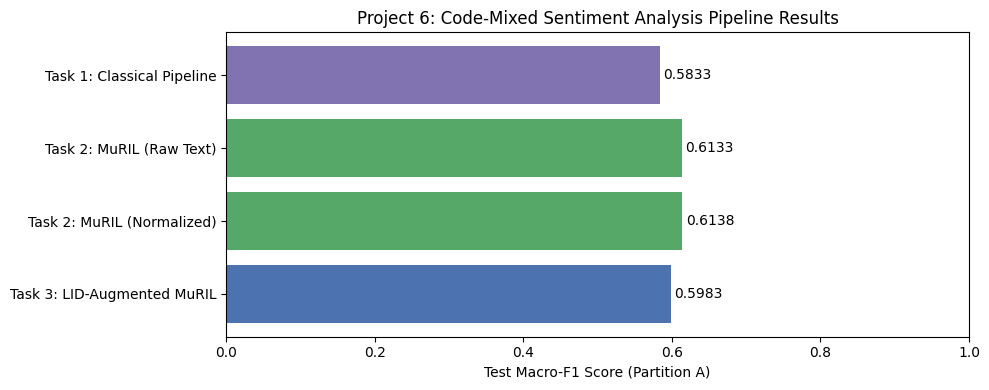

In [11]:
import matplotlib.pyplot as plt

comparison_results = {
    "Task 1: Classical Pipeline": test_macro_f1,
    "Task 2: MuRIL (Raw Text)": raw_evaluation.metrics["test_macro_f1"],
    "Task 2: MuRIL (Normalized)": norm_evaluation.metrics["test_macro_f1"],
    "Task 3: LID-Augmented MuRIL": task3_macro_f1
}

print("=== FINAL MACRO-F1 SCORES ===")
for task_name, score in comparison_results.items():
    print(f"{task_name:35s} : {score:.4f}")

labels = list(comparison_results.keys())[::-1]
scores = list(comparison_results.values())[::-1]

plt.figure(figsize=(10, 4))
bars = plt.barh(labels, scores, color=["#4c72b0", "#55a868", "#55a868", "#8172b2"])

for bar, score in zip(bars, scores):
    plt.text(score + 0.005, bar.get_y() + bar.get_height()/2, f"{score:.4f}", va="center")

plt.xlim(0, 1.0)
plt.xlabel("Test Macro-F1 Score (Partition A)")
plt.title("Project 6: Code-Mixed Sentiment Analysis Pipeline Results")
plt.tight_layout()

plt.savefig(data_dir / "final_comparison.png", dpi=150)
plt.show()